In [11]:
import pandas as pd
import numpy as np

file_path = "netflix_titles.csv"

df = pd.read_csv(file_path)   # or: netflix = pd.read_csv(file_path)

df.head()

#rows n columns
df.shape

(8807, 12)

In [12]:
#column names
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [13]:
# information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [14]:
# Check missing values
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [16]:
# Filling the missing values with "Unknown"

df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['rating'] = df['rating'].fillna('Unknown')
df['duration'] = df['duration'].fillna('Unknown')
df['date_added'] = df['date_added'].fillna('Unknown')

In [17]:
# rechecking
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

In [18]:
# Checking for duplicate rows

df.duplicated().sum()

np.int64(0)

In [19]:
# Count the Movies and TV Shows

df['type'].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

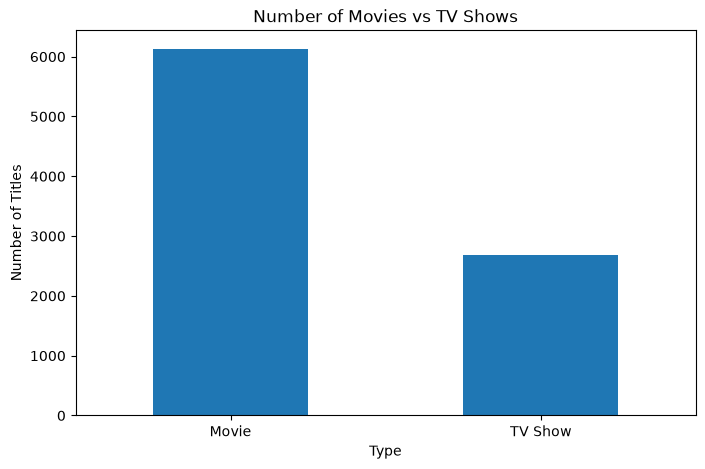

In [24]:
import matplotlib.pyplot as plt

type_counts = df['type'].value_counts()

# creating bar chart
plt.figure(figsize=(8, 5))
type_counts.plot(kind='bar')
plt.title('Number of Movies vs TV Shows')
plt.xlabel('Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.show()

In [25]:
# Counting the most common ratings
rating_counts = df['rating'].value_counts()

# Displaying the top 10 ratings
rating_counts.head(10)

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64

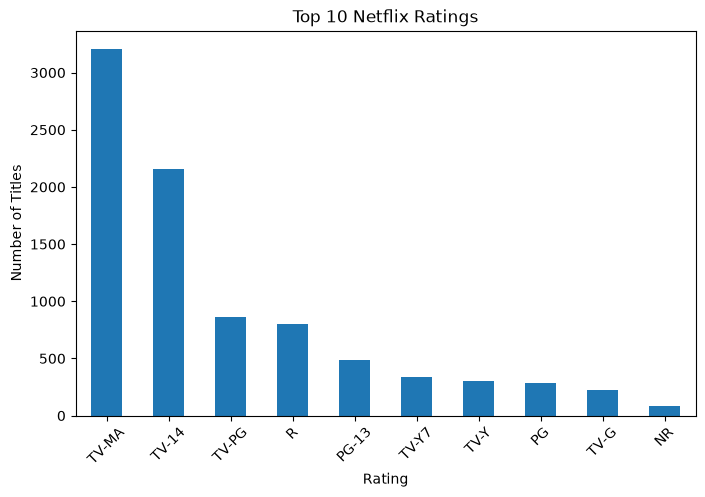

In [26]:
# Creating bar chart for the top 10 ratings
rating_counts.head(10).plot(kind='bar', figsize=(8,5))

plt.title('Top 10 Netflix Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

# Analysis
-- This chart shows the **10 most common ratings** in the Netflix dataset

-- TV-MA is the most frequent rating, followed by TV-14 and TV-PG

-- This indicates that a large portion of Netflix content is aimed at mature audiences

-- Ratings like TV-Y, TV-G, and NR appear much less frequently

In [32]:
# Counting the titles by country
country_counts = df['country'].dropna().str.split(', ').explode().value_counts()

# Displaying top 10 countries
country_counts.head(10)

country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64

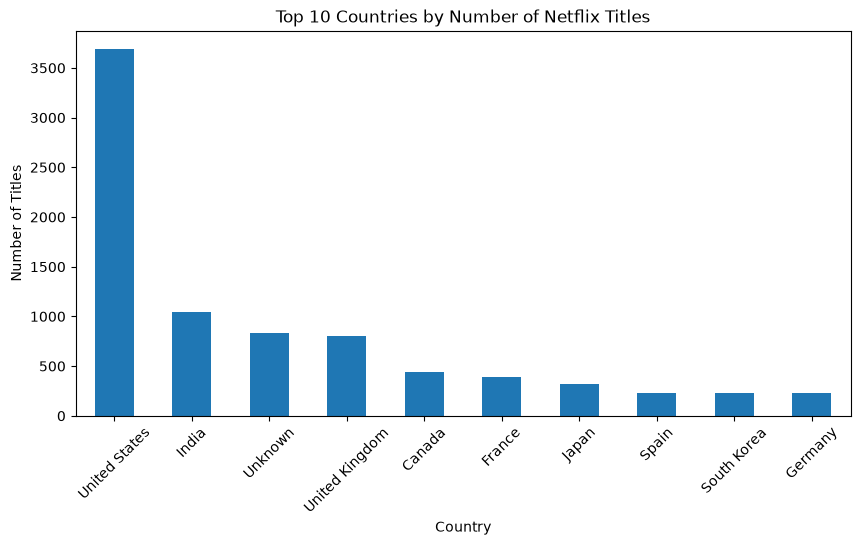

In [33]:
# Creating bar chart for top 10 countries
country_counts.head(10).plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Countries by Number of Netflix Titles')
plt.xlabel('Country')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

# Analysis
-- This chart shows the Top 10 countries with the highest number of Netflix titles
 **United States** produces the most content by a large margin
 **India** and the **UK** are the next biggest contributors
Many titles have "Unknown" country, which means the country information is missing in the dataset
Other countries like Canada, France, Japan, Spain, South Korea, and Germany also contribute a significant number of titles

In [35]:
# Converting the date_added into datetime format
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

# Counting titles that are added each year
year_counts = df['date_added'].dt.year.value_counts().sort_index()

# Displaying the result
year_counts

date_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      10
2014.0      23
2015.0      73
2016.0     418
2017.0    1164
2018.0    1625
2019.0    1999
2020.0    1878
2021.0    1498
Name: count, dtype: int64

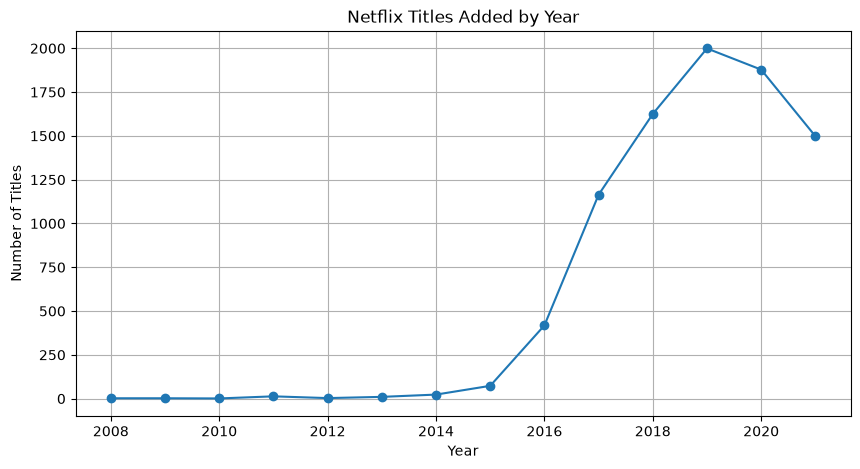

In [36]:
# Creating a line chart
year_counts.plot(kind='line', figsize=(10,5), marker='o')

plt.title('Netflix Titles Added by Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.show()

In [37]:
# Counting Movies and TV Shows
type_counts = df['type'].value_counts()

# Displaying the counts
type_counts

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

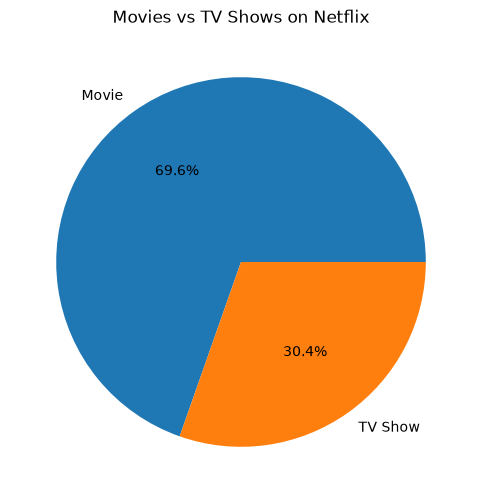

In [39]:
# Creating a pie chart
type_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))

plt.title('Movies vs TV Shows on Netflix')
plt.ylabel('')

plt.show()

Analysis


--Comparing what type of content is more popular on Netflix in a pie chart this time

# Conclusion
-- In this project, I explored the Netflix dataset to understand what kind of content is available on the platform. Through the analysis, a few clear patterns stood out:

Movies make up a much larger share of the catalog compared to TV Shows.
Most titles are rated for mature audiences (especially TV-MA and TV-14).
The United States produces the highest number of titles, followed by India and the United Kingdom.
A noticeable number of titles have missing country information.

-- Overall, this analysis gave me a better understanding of how Netflix’s content is distributed in terms of type, ratings, and countries. It also helped me practice working with real-world data using Python and Pandas.